In [36]:
# Import modules
import math
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
RANDOM_STATE=42

In [37]:
# Load Data
data = fetch_california_housing(as_frame=True)
X = data.data
y = data.target
print(X.shape)
print(Y.shape)

(20640, 8)
(20640,)


In [38]:
# Split data into Train Test Set(80/20)
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=RANDOM_STATE)
print(X_train.shape)
print(X_test.shape)

(16512, 8)
(4128, 8)


In [39]:
# Feature Scaling -- Using Standard Scaling method
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



In [83]:
# Helper function to compute cost

def compute_cost(X,y,w,b):
    m = X.shape[0]
    cost = 0

    y_arr = np.asarray(y)
    
    for i in range(m):
        f_wb_i = np.dot(X[i], w) + b
        cost += (f_wb_i - y_arr[i])**2

    cost = cost/(2*m)
    return cost

# Initialize SGDRegressor class -- Since LinearRegressor class in scikit learn by default uses Normal equation for calculating weights.

model = SGDRegressor(
    loss='squared_error',         # Standard Linear regression using MSE cost function
    penalty=None,
    eta0=0.00005,                 # Learning rate
    learning_rate='constant',
    warm_start=True,              # Allows continous training iteratively across epochs
    max_iter=1,                   # 1 internal iteration per epoch
    random_state=RANDOM_STATE,
    tol=None,
)


In [88]:
# Iterative training of the model and track the cost function

epochs = 200
train_loss = []

for epoch in range(epochs):
    model.fit(X_train_scaled,y_train) # Train one epoch of gradient descent update

    # Extract weighs learned by model
    w = model.coef_
    b = model.intercept_[0]

    # Compute cost
    train_cost = compute_cost(X_train_scaled,y_train,w,b)
    train_loss.append(train_cost)

    if epoch % math.ceil(epochs/10)==0:
        print(f"Epoch {epoch} Cost: {train_cost:0.4e}")

w_final = model.coef_
b_final = model.intercept_[0]

print(f"Final weight and bias for the model are : {w_final} , {b_final:0.4e}")

Epoch 0 Cost: 2.5901e-01
Epoch 20 Cost: 2.5901e-01
Epoch 40 Cost: 2.5901e-01
Epoch 60 Cost: 2.5901e-01
Epoch 80 Cost: 2.5901e-01
Epoch 100 Cost: 2.5901e-01
Epoch 120 Cost: 2.5901e-01
Epoch 140 Cost: 2.5901e-01
Epoch 160 Cost: 2.5901e-01
Epoch 180 Cost: 2.5901e-01
Final weight and bias for the model are : [ 0.85474722  0.12070742 -0.29794968  0.33389252 -0.00204433 -0.03886776
 -0.89746678 -0.86836733] , 2.0721e+00


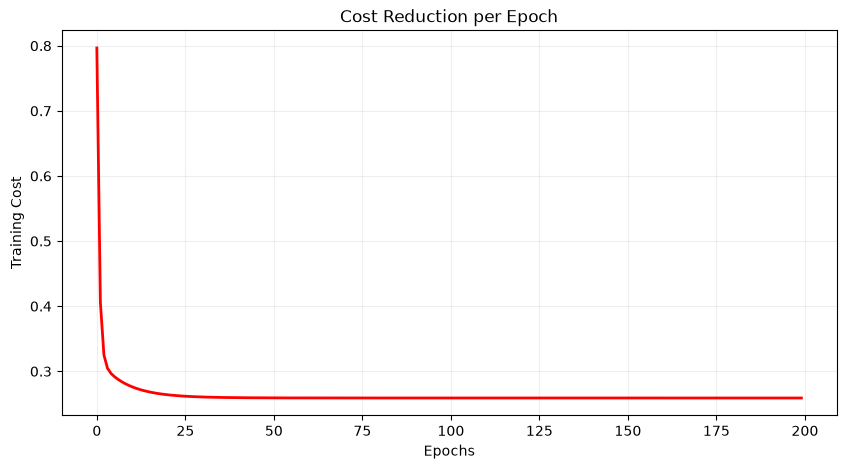

In [85]:
# Plot the loss curve
plt.figure(figsize=(10,5))
plt.title("Cost Reduction per Epoch")
plt.xlabel("Epochs")
plt.ylabel("Training Cost")
plt.grid(True,alpha=0.2)
plt.plot(train_loss,linewidth=2,color='red')
plt.show()

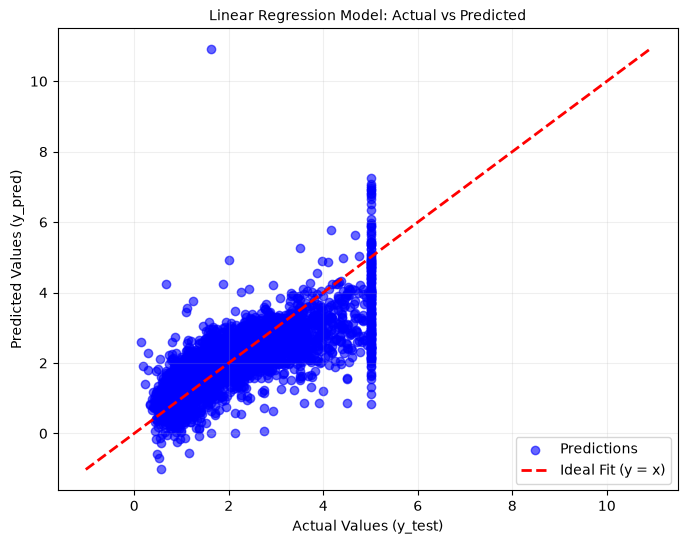

In [97]:
# Test Results
y_pred = model.predict(X_test_scaled)

# Plot the Actual vs Predicted
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color="b", alpha=0.6, label="Predictions")

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="r",
    linewidth=2,
    linestyle='--',
    label="Ideal Fit (y = x)",
)

plt.xlabel("Actual Values (y_test)")
plt.ylabel("Predicted Values (y_pred)")
plt.title("Linear Regression Model: Actual vs Predicted", fontsize=10)
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()